In [16]:
import matplotlib.pyplot as plt
from algorithms.tss_file import TSSFile
import os
import numpy as np
from algorithms.wfm_edge import WFM_edge

In [2]:
def find_file(filename, search_dir):
    for root, dirs, files in os.walk(search_dir):
        if filename in files:
            return root
    return None

In [ ]:
folder = r'Y:\TESTDATA\DP\2026\07\15'
tss_file = 'Tek20260715T125623.tss'
path = find_file(tss_file, folder)
tss = TSSFile(path, tss_file, source='Local')
channel_labels = tss.channel_labels
num = len(channel_labels.keys())
print(channel_labels)

{'ch1': 'VGO_LS', 'ch2': 'Is', 'ch3': 'Vd', 'ch4': 'VGO_HS', 'ch5': 'FLT', 'ch7': 'Ig', 'ch8': 'IL'}


In [13]:
channels_to_plot = ['ch3', 'ch2']  # Specify the channels you want to plot
num = len(channels_to_plot) + 1

Peak dI/dt during turn-off: -35.70 A/ns
18.24000000000205


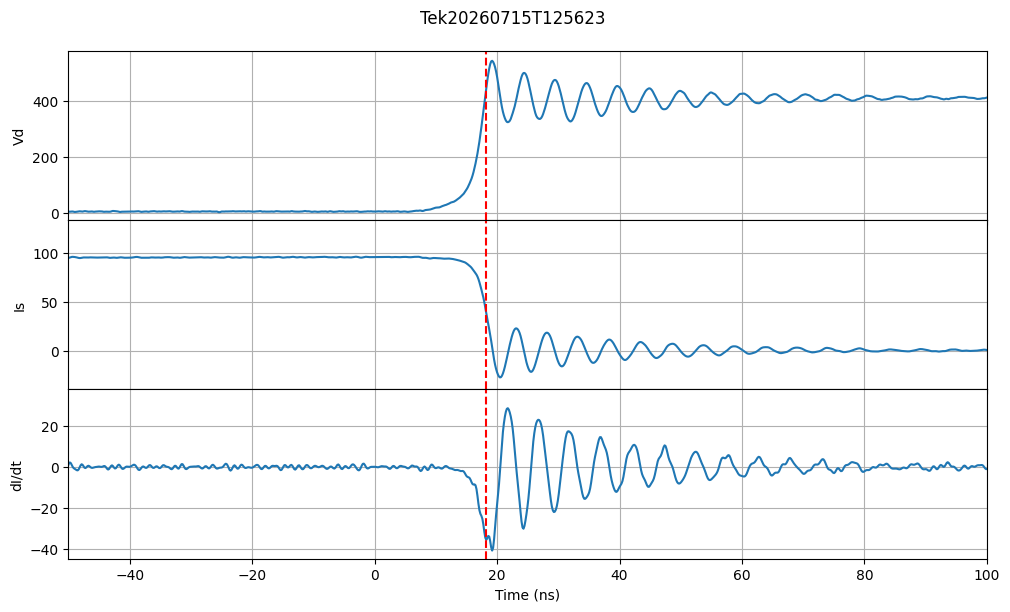

In [22]:
fig, axs = plt.subplots(num, 1, sharex=True, figsize=(10, num*2))
fig.suptitle(tss_file[:-4])
fig.tight_layout()
fig.subplots_adjust(hspace=0)
time1 = tss.waveforms[list(channel_labels.keys())[0]].time_for_frame()*1e9
is_value = tss.waveforms['ch2'].values_for_frame(0)
didt = np.gradient(is_value, time1)
time_range = [-50, 100]

is_edges = WFM_edge(is_value, time1, falling_edge_number=2,
                            rising_edge_number=1,
                            peak_width=1,
                            peak_distance=10, 
                            sigma=100,
                            margin_ratio=20,)
idx_off_1 = is_edges.get_edge(1, 'falling', 90)['thresh_idx']
idx_off_2 = is_edges.get_edge(1, 'falling', 10)['thresh_idx']
time_turn_off = time1[idx_off_1:idx_off_2]
is_turn_off = is_value[idx_off_1:idx_off_2]
didt_off = np.gradient(is_turn_off, time_turn_off)
didt_off_peak = min(didt_off)
print(f"Peak dI/dt during turn-off: {didt_off_peak:.2f} A/ns")
idxmin = np.argmin(didt_off)
time2 = time1[idxmin + idx_off_1]
print(time2)

index = 0
for channel in channels_to_plot:
    values = tss.waveforms[channel].values_for_frame(0)
    axs[index].plot(time1, values)
    axs[index].set_ylabel(channel_labels[channel])
    axs[index].grid(True)
    axs[index].axvline(x=time2, color='r', linestyle='--')
    index += 1

axs[index].plot(time1, didt)
axs[index].set_ylabel('dI/dt')
axs[index].grid(True)
axs[index].axvline(x=time2, color='r', linestyle='--')

plt.xlabel('Time (ns)')
plt.xlim(time_range)
plt.show()